In [1]:
import numpy as np
import gc
import os
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import random
import torch
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import DataLoader, Subset
import IPython.display as ipd
import uuid


In [2]:
def augment_audio(input_path):
    """
    Аугментирует аудиофайл и сохраняет результат

    Args:
        input_path: путь к исходному файлу
    """
    waveform, sr = torchaudio.load(input_path, )
    if sr != 16000:
        waveform = torchaudio.transforms.Resample(sr, 16000)(waveform)
        sr = 16000
    aug_type = random.choice([
        'time_stretch',
        'pitch_shift',
        'add_noise',
        'time_shift',
        'volume_change',
        'combined'
    ])

    # Time stretch - изменение скорости
    if aug_type == 'time_stretch':
        rate = random.uniform(0.85, 1.15)  # Было 0.8-1.2, стало 0.5-1.8
        resampler = torchaudio.transforms.Resample(sr, int(sr * rate))
        augmented = resampler(waveform)
        if augmented.shape[1] > waveform.shape[1]:
            augmented = augmented[:, :waveform.shape[1]]
        else:
            pad_size = waveform.shape[1] - augmented.shape[1]
            augmented = torch.nn.functional.pad(augmented, (0, pad_size))

    # Pitch shift - изменение тона
    elif aug_type == 'pitch_shift':
        n_steps = random.uniform(-2, 2)  # Было -3..3, стало -8..8 (почти октава)
        rate = 2.0 ** (-n_steps / 12.0)
        new_sr = int(sr * rate)
        resampler = torchaudio.transforms.Resample(sr, new_sr)
        augmented = resampler(waveform)
        resampler_back = torchaudio.transforms.Resample(new_sr, sr)
        augmented = resampler_back(augmented)
        if augmented.shape[1] > waveform.shape[1]:
            augmented = augmented[:, :waveform.shape[1]]
        else:
            pad_size = waveform.shape[1] - augmented.shape[1]
            augmented = torch.nn.functional.pad(augmented, (0, pad_size))

    # Добавление шума
    elif aug_type == 'add_noise':
        noise_level = random.uniform(0.001, 0.01)  # Было 0.001-0.015, стало 0.005-0.05
        noise = torch.randn_like(waveform) * noise_level
        augmented = torch.clamp(waveform + noise, -1.0, 1.0)

    # Сдвиг во времени
    elif aug_type == 'time_shift':
        shift = random.randint(0, waveform.shape[1] - 1)
        augmented = torch.roll(waveform, shifts=shift, dims=1)

    # Изменение громкости
    elif aug_type == 'volume_change':
        volume_factor = random.uniform(0.7, 1.3)  # Было 0.5-1.5, стало 0.1-2.5
        augmented = torch.clamp(waveform * volume_factor, -1.0, 1.0)

    # Комбинация нескольких
    elif aug_type == 'combined':
        # Шум
        noise_level = random.uniform(0.003, 0.03)  # Было 0.001-0.008, стало 0.003-0.03
        augmented = waveform + torch.randn_like(waveform) * noise_level
        # Громкость
        volume_factor = random.uniform(0.3, 2.0)  # Было 0.7-1.3, стало 0.3-2.0
        augmented = augmented * volume_factor
        # Сдвиг
        shift = random.randint(0, augmented.shape[1] - 1)
        augmented = torch.roll(augmented, shifts=shift, dims=1)
        augmented = torch.clamp(augmented, -1.0, 1.0)

    # Сохраняем результат
    directory = os.path.dirname(input_path)
    filename = os.path.basename(input_path)
    name, ext = os.path.splitext(filename)
    unique_id = uuid.uuid4().hex[:8]
    output_path = os.path.join(directory, f"{name}_aug_{aug_type}_{unique_id}{ext}")
    torchaudio.save(output_path, augmented, sr)
    print(f"Сохранено: {output_path}")
    print(f"Форма: {augmented.shape}, Частота: {sr}")

In [3]:
class AudioDataset(Dataset):
    def __init__(self, dir, transform=T.MelSpectrogram(sample_rate=16000,n_mels=64,n_fft=1024,hop_length=512),fixed_time_frames=None):
        self.transform = transform
        self.dir = dir
        self.fixed_time_frames = fixed_time_frames
        self.audio_files = []
        self.labels = []
        self.class_names = sorted(os.listdir(dir))

        for label_idx, class_name in enumerate(self.class_names):
            class_path = os.path.join(self.dir, class_name)
            for audio_file in os.listdir(class_path):
                self.audio_files.append(os.path.join(class_path, audio_file))
                self.labels.append(label_idx)

    def __len__(self):
        return len(self.audio_files)

    def __getitem__(self, idx):

        audio_path = self.audio_files[idx]
        label = self.labels[idx]
        waveform, sample_rate = torchaudio.load(audio_path)

        if self.transform:
            waveform = self.transform(waveform)

        if self.fixed_time_frames is not None:
            if waveform.shape[-1] > self.fixed_time_frames:
                waveform = waveform[:, :, :self.fixed_time_frames]
            else:
                pad_size = self.fixed_time_frames - waveform.shape[-1]
                waveform = torch.nn.functional.pad(waveform, (0, pad_size))

        return waveform, label

    def get_class_name(self, idx):
        """Возвращает имя класса по индексу"""
        return self.class_names[idx]

    def augment_to(self, N):
        """Аугментирует каждый класс до N файлов."""
    
        for class_name in self.class_names:
            class_path = os.path.join(self.dir, class_name)
    
            # Только оригинальные файлы
            original_files = [
                f for f in os.listdir(class_path)
                if "_aug_" not in f
            ]
    
            if len(original_files) == 0:
                continue
            
            class_size = len(os.listdir(class_path))
    
            while class_size < N:
                file = random.choice(original_files)
                full_path = os.path.join(class_path, file)
    
                augment_audio(full_path)
    
                class_size = len(os.listdir(class_path))
                print(f"{class_name}: {class_size}/{N}")
                gc.collect()

In [4]:
dataset_temp = AudioDataset("data02")
lengths = []
for i in range(min(100, len(dataset_temp))):
    spec, _ = dataset_temp[i]
    lengths.append(spec.shape[-1])

avg_length = int(np.mean(lengths))
print(f"Средняя длина спектрограммы: {avg_length} кадров")

full_dataset = AudioDataset("data02", fixed_time_frames=avg_length)
full_dataset.augment_to(2000)
total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.2 * total_size)
test_size = total_size - train_size - val_size
torch.seed(42)
shuffled_indices = torch.randperm(len(full_dataset)).tolist()

train_indices = shuffled_indices[:train_size]
val_indices = shuffled_indices[train_size:train_size+val_size]
test_indices = shuffled_indices[train_size+val_size:]

train_dataset = Subset(full_dataset, train_indices)
val_dataset = Subset(full_dataset, val_indices)
test_dataset = Subset(full_dataset, test_indices)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")


Средняя длина спектрограммы: 259 кадров
Сохранено: data02\cel\013__[cel][nod][cla]0025__3_aug_volume_change_b4ad2f06.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 389/2000
Сохранено: data02\cel\[cel][cla]0108__2_aug_time_stretch_6a7abccb.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 390/2000
Сохранено: data02\cel\[cel][cla]0121__1_aug_add_noise_6fc42eda.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 391/2000
Сохранено: data02\cel\[cel][jaz_blu]0066__1_aug_add_noise_1abe760d.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 392/2000
Сохранено: data02\cel\[cel][pop_roc]0101__2_aug_combined_0cb819f7.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 393/2000
Сохранено: data02\cel\[cel][pop_roc]0018__1_aug_pitch_shift_f2930736.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 394/2000
Сохранено: data02\cel\042__[cel][nod][cla]0042__2_aug_time_stretch_9adf07b8.wav
Форма: torch.Size([2, 48000]), Частота: 16000
cel: 395/2000
Сохранено: data02\cel\[cel][

TypeError: seed() takes 0 positional arguments but 1 was given

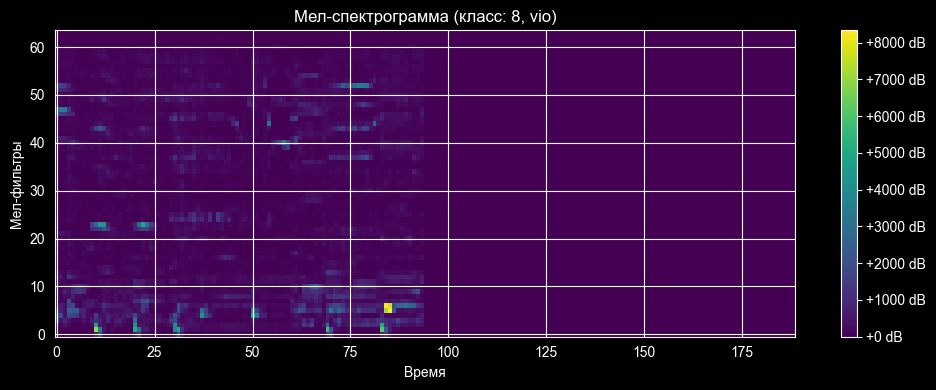

Класс: vio
Индекс в val_dataset: 2
Индекс в full_dataset: 8069
Файл: 072__[vio][dru][cou_fol]2188__2_aug_time_shift.wav


In [43]:
batch_data, batch_labels = next(iter(val_loader))

# Выбор элемента из батча (0-63)
element_idx = 2
spec = batch_data[element_idx, 0]
label = batch_labels[element_idx].item()

class_name = full_dataset.get_class_name(label)

plt.figure(figsize=(10, 4))
plt.imshow(spec.numpy(), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Мел-спектрограмма (класс: {label}, {class_name})')
plt.xlabel('Время')
plt.ylabel('Мел-фильтры')
plt.tight_layout()
plt.show()

original_idx = val_indices[element_idx]
audio_path = full_dataset.audio_files[original_idx]

print(f"Класс: {class_name}")
print(f"Индекс в val_dataset: {element_idx}")
print(f"Индекс в full_dataset: {original_idx}")
print(f"Файл: {os.path.basename(audio_path)}")

waveform, sr = torchaudio.load(audio_path)
ipd.Audio(waveform.numpy(), rate=sr)